In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans

In [2]:
img_path = "../output_videos/cropped_img.jpg"
img = cv2.imread(img_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

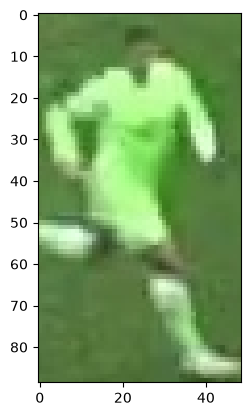

In [3]:
plt.imshow(img)
plt.show()

#### take the top half of the img


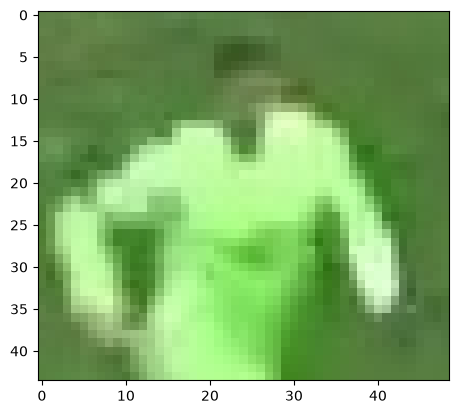

In [4]:
top_half = img[0: int(img.shape[0]/2), :]
plt.imshow(top_half)
plt.show()

#### Cluster the image into two clusters

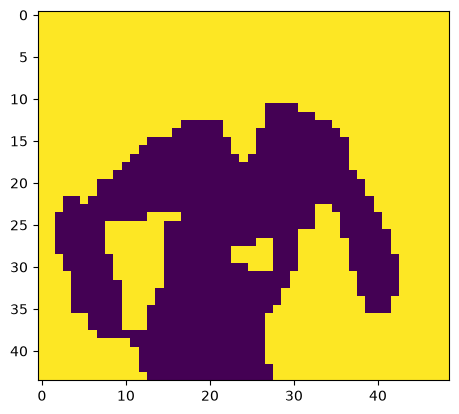

In [6]:
# reshape the image into 2d array
img_2D = top_half.reshape(-1, 3)

# perform k-means clustering with 2 clusters
kmeans = KMeans(n_clusters=2, random_state=77)
kmeans.fit(img_2D)

# get the cluster labels
labels = kmeans.labels_

# reshape the labels into the original image shape
clustered_img = labels.reshape(top_half.shape[0], top_half.shape[1])

# display the clustered image
plt.imshow(clustered_img)
plt.show()

In [7]:
corner_clusters = [clustered_img[0, 0], clustered_img[0, -1], clustered_img[-1, 0], clustered_img[-1, -1]]
non_player_cluster = max(set(corner_clusters), key=corner_clusters.count)

print(non_player_cluster)

1


In [8]:
player_cluster = 1 - non_player_cluster

print(player_cluster)

0


In [10]:
kmeans.cluster_centers_[player_cluster]

array([171.38378378, 235.65405405, 142.8472973 ])